# 04 - Uncertainty-guided active learning (RQ3)
Question: can the classifier reach good performance with fewer radiologist-labeled lesions if it chooses which lesions to ask about?

Strategies: `random` (control), `entropy` (MC dropout), `bald` (mutual information), `coreset` (diverse samples, k-center greedy). Everything starts from the same small labeled set; labels are revealed in rounds (the radiologist is **simulated** by revealing labels we already have). Repeated over several seeds.

Time: roughly 30-90 minutes depending on pool size, strategies and seeds (reduce `al_seeds`, `al_strategies`, `al_rounds` in the config for a faster run).

In [7]:
# ---- 1. connect Drive, install, load the code ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Not running in Colab:', e)
!pip -q install pydicom
import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
CODE_DIR = '/content/drive/MyDrive/mammo_semcom'          # <-- the folder you uploaded (contains src/ and notebooks/)
sys.path.insert(0, CODE_DIR)
from src.config import Cfg

cfg = Cfg(
    cbis_root = '/content/drive/MyDrive/CBIS-DDSM',        # raw data folder: NOT needed after notebook 00 (the cache is used)
    work_dir  = '/content/drive/MyDrive/mammo_semcom_work', # <-- all caches, models, results and figures go here
    max_images = 0,                                         # 0 = everything; try 150 first for a quick dry run
).ensure()
cfg.save()
print(cfg.work_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/mammo_semcom_work


In [8]:
from src import data, viz, train as T
from src.pipeline import Receiver, diagnose_all
from src.metrics import *
images, masks, images_df, abn_df = data.load_cache(cfg)
tr_idx = images_df[images_df.split == 'train'].img_idx.values
va_idx = images_df[images_df.split == 'val'].img_idx.values
abn_tr = abn_df[abn_df.split == 'train'].reset_index(drop=True)
abn_va = abn_df[abn_df.split == 'val'].reset_index(drop=True)
abn_te = abn_df[abn_df.split == 'test'].reset_index(drop=True)
te_df = images_df[(images_df.split == 'test') & (~images_df.mixed)].reset_index(drop=True)   # image-level test set
print(len(tr_idx), 'train /', len(va_idx), 'val images |', len(te_df), 'test images | device:', T.DEVICE)

106 train / 22 val images | 22 test images | device: cuda


In [9]:
from src.pipeline import *
P_pool, y_pool = T.gt_patches(images, abn_tr, cfg), abn_tr.label.values
P_va, y_va = T.gt_patches(images, abn_va, cfg), abn_va.label.values
P_te, y_te = T.gt_patches(images, abn_te, cfg), abn_te.label.values
print('pool', len(y_pool), '| val', len(y_va), '| test', len(y_te), '| start labels', int(cfg.al_init_frac * len(y_pool)),
      '| per round', int(cfg.al_step_frac * len(y_pool)), '| rounds', cfg.al_rounds)

pool 115 | val 33 | test 23 | start labels 5 | per round 3 | rounds 6


## 2. Reference: all pool labels

In [10]:
from torch.utils.data import DataLoader
npos = int(y_pool.sum())
m_full, _ = T.fit_classifier(DataLoader(T.ArrDS(P_pool, y_pool, True), batch_size=cfg.clf_bs, shuffle=True), P_va, y_va, cfg,
                             cfg.al_epochs, 999, (len(y_pool) - npos) / max(npos, 1), verbose=False)
full_auc = auc_safe(y_te, T.classifier_probs(m_full, P_te)); target = 0.95 * full_auc
print('AUC with all labels:', round(full_auc, 3), '| target (95% of it):', round(target, 3))

AUC with all labels: 0.644 | target (95% of it): 0.612


## 3. Run the active-learning experiment

In [12]:
import numpy as np
# Monkey-patch np.trapz for compatibility with NumPy 2.0+
if not hasattr(np, 'trapz'):
    try:
        np.trapz = np.trapezoid
    except AttributeError:
        from scipy.integrate import trapezoid
        np.trapz = trapezoid

al = active_learning(cfg, P_pool, y_pool, P_va, y_va, P_te, y_te)
al.to_csv(cfg.path('results', 'active_learning_runs.csv'), index=False)
curve, summ = al_summary(al, target)
curve.to_csv(cfg.path('results', 'active_learning_curve.csv'), index=False); summ.to_csv(cfg.path('results', 'active_learning_summary.csv'), index=False)
summ.round(3)

seed 0 | random   | final AUC 0.409 with 28 labels
seed 0 | entropy  | final AUC 0.576 with 28 labels
seed 0 | bald     | final AUC 0.561 with 28 labels
seed 0 | coreset  | final AUC 0.500 with 28 labels
seed 1 | random   | final AUC 0.386 with 28 labels
seed 1 | entropy  | final AUC 0.432 with 28 labels
seed 1 | bald     | final AUC 0.455 with 28 labels
seed 1 | coreset  | final AUC 0.500 with 28 labels
seed 2 | random   | final AUC 0.568 with 28 labels
seed 2 | entropy  | final AUC 0.568 with 28 labels
seed 2 | bald     | final AUC 0.636 with 28 labels
seed 2 | coreset  | final AUC 0.545 with 28 labels


,strategy,ALC,labels_to_target
0,bald,0.573,13
1,coreset,0.544,13
2,entropy,0.583,13
3,random,0.532,13


## 4. Figure: performance vs labels, and gain over random

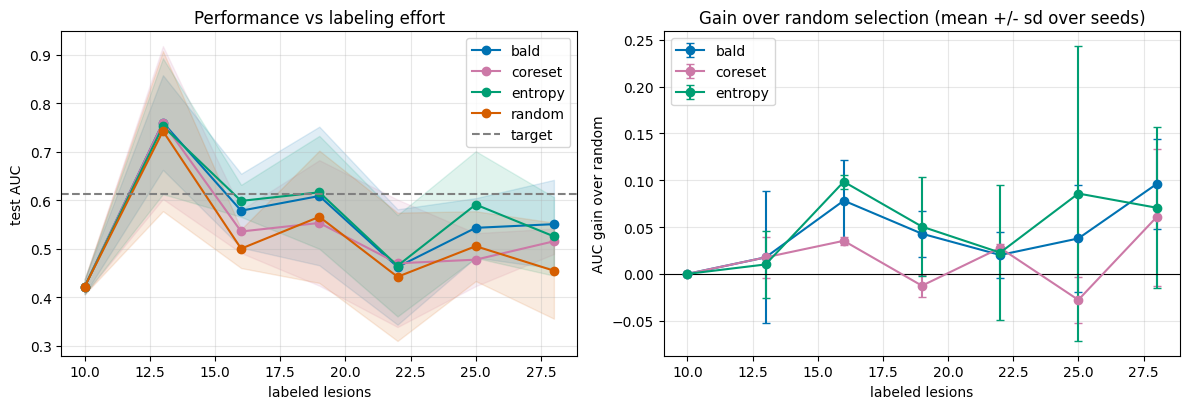

In [13]:
viz.plot_al(al, path=cfg.path('figures', '04_active_learning.png'), target=target)

## 5. Is any gain real? Paired comparison of the area under the learning curve (ALC) against random, per seed

In [14]:
def _alc(g):
    g = g.sort_values('n_labeled'); return area_under_curve(g.n_labeled, g.AUC)
alc = pd.DataFrame({s: {seed: _alc(g[g.seed == seed]) for seed in g.seed.unique()} for s, g in al.groupby('strategy')})
out = []
for s in [c for c in alc.columns if c != 'random']:
    d = (alc[s] - alc['random']).values
    out.append(dict(strategy=s, mean_ALC_gain=d.mean(), sd=d.std(ddof=1) if len(d) > 1 else np.nan, seeds=len(d), seeds_better_than_random=int((d > 0).sum())))
alc_tab = pd.DataFrame(out).round(4); alc_tab.to_csv(cfg.path('results', 'active_learning_alc_gain.csv'), index=False); alc_tab

,strategy,mean_ALC_gain,sd,seeds,seeds_better_than_random
0,bald,0.0408,0.0178,3,3
1,coreset,0.0118,0.0112,3,3
2,entropy,0.0505,0.0410,3,3


## How to report this
* If a strategy's ALC gain is clearly above 0 across seeds and its curve sits above `random`, report the label saving (`labels_to_target` in the summary table).
* If curves overlap, report it as **no reliable label saving in this setting** and say why it is plausible (a strong pretrained model, a small and relatively easy pool, few seeds). A clean negative result is a legitimate finding.
* With only a few seeds, differences below the seed-to-seed standard deviation should not be claimed.

Next: `05_summary_and_export.ipynb`.